# ✅ RESOLUCIÓN (docente): ventas semanales de una tienda
**Dataset:** `ventas_semanales_tienda.csv` · 104 filas · 7 columnas (2024–2025, datos **sintéticos**).
**Tiempo:** ~10 minutos · **Entregable:** notebook con gráficos + interpretación.

> Recordá: usá **siempre** `fig, ax = plt.subplots()`. Un gráfico sin título, sin etiquetas y sin unidades no cuenta.

## 1. Preparación
Cargá `ventas_semanales_tienda.csv` (parseando `fecha`), mostrá `head()`, `info()` y `describe()`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('ventas_semanales_tienda.csv', parse_dates=['fecha'])
print(df.shape)
df.head()

(104, 7)


,fecha,ventas_A,ventas_B,ventas_C,ventas_D,inversion_publicidad,ticket_promedio
0,2024-01-01,318.0,314.0,195.0,140.0,17.2,19620.0
1,2024-01-08,419.0,318.0,178.0,166.0,20.2,13320.0
2,2024-01-15,408.0,308.0,184.0,174.0,17.8,20600.0
3,2024-01-22,342.0,341.0,187.0,145.0,18.2,10670.0
4,2024-01-29,386.0,308.0,200.0,151.0,15.3,10690.0


## 2. Gráfico único (control total)
Con `fig, ax = plt.subplots(figsize=...)`, graficá **ventas_A** y **ventas_B** a lo largo del tiempo.
**Personalización obligatoria:** colores/estilos distintos por línea · grilla · título descriptivo · ejes con unidades · leyenda.

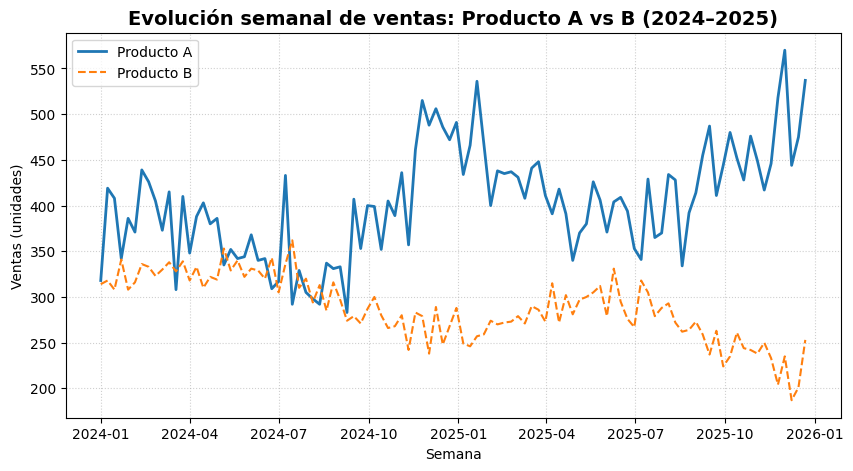

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df['fecha'], df['ventas_A'], label='Producto A', color='tab:blue', linewidth=2)
ax.plot(df['fecha'], df['ventas_B'], label='Producto B', color='tab:orange', linestyle='--')
ax.set_title('Evolución semanal de ventas: Producto A vs B (2024–2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Semana')
ax.set_ylabel('Ventas (unidades)')
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

## 3. Layout comparativo (subplots)
Creá una nueva Figure con **1 fila y 2 columnas** (`figsize` ancho):
- **Izquierda:** histograma de `ticket_promedio`.
- **Derecha:** diagrama de dispersión `inversion_publicidad` (X) vs `ventas_A` (Y).

Cada Axes con su título y sus ejes con unidades.

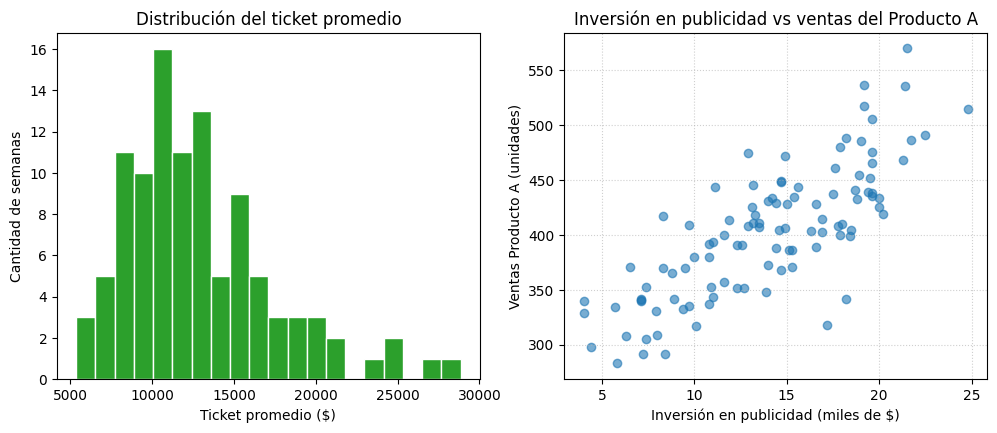

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

axes[0].hist(df['ticket_promedio'], bins=20, color='tab:green', edgecolor='white')
axes[0].set_title('Distribución del ticket promedio')
axes[0].set_xlabel('Ticket promedio ($)')
axes[0].set_ylabel('Cantidad de semanas')

axes[1].scatter(df['inversion_publicidad'], df['ventas_A'], alpha=0.6, color='tab:blue', label='Semanas')
axes[1].set_title('Inversión en publicidad vs ventas del Producto A')
axes[1].set_xlabel('Inversión en publicidad (miles de $)')
axes[1].set_ylabel('Ventas Producto A (unidades)')
axes[1].grid(True, linestyle=':', alpha=0.6)
plt.show()

## 4. Refinamiento
a) Agregá en el Axes de la derecha una **línea de tendencia** con `np.polyfit(x, y, 1)`, con `label` y `legend()`.
b) Llamá a `fig.tight_layout()`.
c) Guardá la figura con `fig.savefig('grafico_ventas.png', dpi=150, bbox_inches='tight')`.

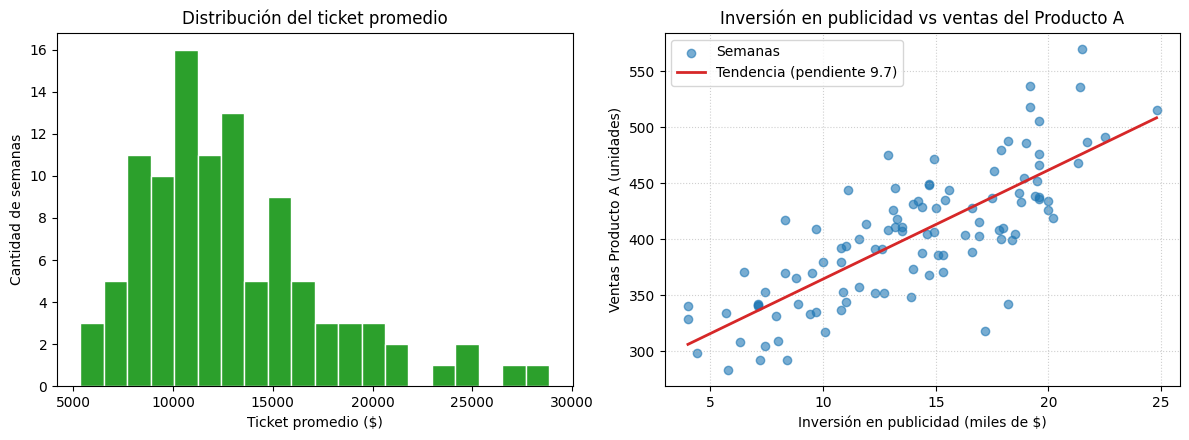

In [4]:
m, b = np.polyfit(df['inversion_publicidad'], df['ventas_A'], 1)
x = np.linspace(df['inversion_publicidad'].min(), df['inversion_publicidad'].max(), 100)
axes[1].plot(x, m*x + b, color='tab:red', linewidth=2, label=f'Tendencia (pendiente {m:.1f})')
axes[1].legend()
fig.tight_layout()
fig.savefig('grafico_ventas.png', dpi=150, bbox_inches='tight')
fig

## 5. Narrativa
En una celda de texto, respondé con tus palabras (3–4 líneas):
- ¿Qué pasa con ventas A y B a lo largo del tiempo?
- ¿Cómo es la forma del histograma del ticket (simétrico, sesgado)?
- ¿Qué relación ves entre inversión y ventas?

**Respuesta modelo:** el Producto A crece (de ~388 a ~482 unidades semanales entre el inicio y el final de 2025) con picos hacia fin de año. mientras que el B cae (de ~321 a ~225). El histograma del ticket está **sesgado a la derecha**: la mediana ($12.090) queda por debajo de la media ($12.892) por unas pocas semanas con tickets altos. La dispersión muestra una **relación positiva** (correlación ≈ 0.78): más inversión en publicidad se asocia con más ventas del Producto A.

## 🎯 Desafío: el gráfico espagueti
a) Graficá las 4 series (`ventas_A` … `ventas_D`) en **un solo Axes**. ¿Se entiende?
b) Resolvelo con una grilla de **2×2 subplots** con `sharex=True, sharey=True`.

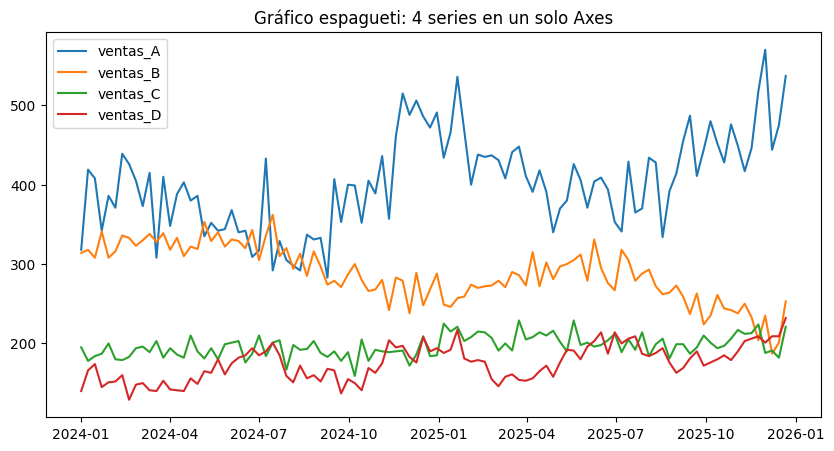

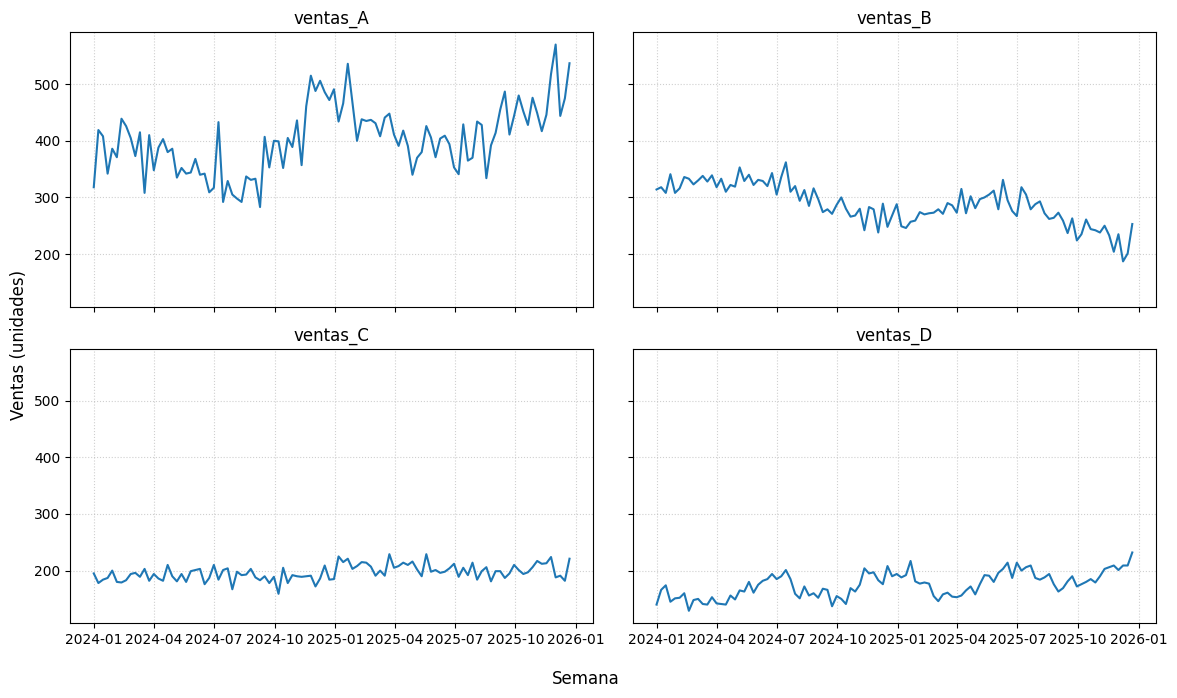

In [5]:
cols = ['ventas_A', 'ventas_B', 'ventas_C', 'ventas_D']

fig, ax = plt.subplots(figsize=(10, 5))
for c in cols:
    ax.plot(df['fecha'], df[c], label=c)
ax.set_title('Gráfico espagueti: 4 series en un solo Axes')
ax.legend()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), cols):
    ax.plot(df['fecha'], df[c])
    ax.set_title(c)
    ax.grid(True, linestyle=':', alpha=0.6)
fig.supxlabel('Semana')
fig.supylabel('Ventas (unidades)')
fig.tight_layout()
plt.show()

**Idea:** separar las series en subplots con los mismos ejes permite compararlas sin que se tapen entre sí.